# Boundary Resolution — Choosing the Next Composition Step

## Abstract

We specify a bounded, auditable procedure for writing a multilayer instance from intent, versioned library descriptions, and unresolved obligations. Building on Paper 1, boundary resolution selects a requirement-scoped mismatch, proposes explicit actions, checks their admissibility, compares alternatives under a declared policy, and records the resulting specification revision. The procedure separates structural design closure from behavioral satisfaction and deployment readiness. It supports top-down decomposition, bottom-up composition, and middle-out revision without requiring every layer to be populated. Its contribution is an explicit decision architecture and a conservative baseline policy, not a demonstrated synthesis engine. All examples are symbolic; no algorithm, workflow, model, or experimental test was executed for this paper. Empirical evaluation belongs to Paper 3.

## 1. Research Question, Contribution, and Claim Boundary

Research question: given required behavior above and described resources below, what precise next action should write a better-supported instance specification? A boundary is a relation between an obligation and its absent, incompatible, ambiguous, or insufficiently supported realization. It is not a geometric gap, an entropy score, or a proof that an entire intent is impossible. The generator writes descriptions and references; it does not need to activate their resources.

| Contribution | Specified here | Not established |
| --- | --- | --- |
| Representation | Decision state, boundaries, candidates, judgments, trace, and outcome records | A universally sufficient ontology |
| Procedure | Finite-frontier selection, conservative guards, explicit revision and stopping | Complete or globally optimal synthesis |
| Baseline policy | Deterministic ordering given pinned inputs and candidate proposals | An empirically best ordering |
| Worked examples | Symbolic state transitions and retained obligations | Measured performance or behavioral correctness |

## 2. Relationship to Paper 1 and Source Grounding

Paper 1 defines descriptions, occurrences, horizontal assembly, vertical packaging, boundary preservation, and evidence-scoped judgments. Paper 2 adds a controller over those rules. Its controller cannot strengthen a claim merely by choosing or packaging it. Langflow provides concrete component interfaces and configuration structures [2]; this paper proposes an additional multilayer planning representation. JSON Schema can express structural assertions [3], while cross-record semantics and behavioral claims require separate criteria. Neither source establishes the proposed controller. This is selective grounding, not a systematic literature review or a novelty claim.

| Paper 1 object | Paper 2 use | Preserved restriction |
| --- | --- | --- |
| Description d=(k,ℓ,C,I,O,Θ,D,E) | Candidate matching and rule operands | Capability prose is not executable proof |
| Occurrence v=(o,k,θ) | Stable identity in branch-local assemblies | Definition reuse does not imply shared occurrence |
| Candidate graph and boundary mappings | Explicit patch target and packaging result | Crossing edges and required unbound inputs survive |
| Mandatory baseline Rᵦ | Stable acceptance reference | Scope cannot shrink silently |
| Met / violated / unknown | Guard and outcome judgments | Unknown never counts as met |
| Trace T and active gaps U | Decision history and current work frontier | Rejected alternatives stay in history, not active gaps |

## 3. Notation and Decision State

Let S=(β,L,Q,J,U,A,F,V,T,b,π). β is the pinned requirement baseline and scope. L is the library snapshot. Q is the current branch specification, containing graphs Gℓ, vertical membership, interface mappings, bindings, and proposed local definitions. J is the judgment ledger; U is the active obligation set; A is the current candidate set. F is a finite frontier of alternative branch states; V records visited semantic states and attempted actions. T is append-only decision history, b is the remaining attempt budget, and π is the versioned policy. Q refines Paper 1’s generated document without replacing it. S is controller context, not a second canonical instance document.

| Field | Record content | Boundary condition |
| --- | --- | --- |
| β | Baseline ID/version; scoped requirement IDs; acceptance criteria; confirmation status | Changes create an explicit new baseline |
| L | Definition keys/versions; rule registry; layer profiles; resource descriptions | No silent refresh during a decision |
| Q | Per-layer graphs, memberships, boundary mappings, bindings, local definitions | Edits are atomic proposed patches |
| J | Judgments and their dependency/evidence scope | Stale judgments stop counting |
| U | Open obligations, including behavioral and activation obligations | No deletion without disposition |
| A | Finite ordered candidate batch for one boundary | Generation limits and truncation disclosed |
| F | Alternative branch snapshots and pending candidates | Finite capacity; discarded branches recorded |
| V | Semantic state keys and attempted-action keys | Layout-only changes do not reset search |
| T | Events, alternatives, reasons, baseline and policy references | History is preserved across rollback |
| b | Nonnegative integer attempt allowance | Every proposal/expansion attempt consumes one |
| π | Ordering, admissibility, limits, canonicalization and closure profile | Versioned; not learned implicitly |

## 4. Requirement and Obligation Records

A requirement records a desired property; an obligation records what remains to justify or realize it. One requirement may have several obligations. Obligations retain their parent requirement and phase. Design obligations concern writing a coherent specification. Behavioral obligations concern what the future system does. Activation obligations concern access and resources needed to run it. Phase does not change mandatory status. Design closure may coexist with deferred behavioral or activation obligations, but satisfaction of all requirements may not be claimed in that state.

| Record | Required fields | Example |
| --- | --- | --- |
| Requirement | ID, baseline, scope, mandatory flag, predicate or qualified claim, acceptance method | R-grounding: preserve source-supported facts |
| Obligation | ID, parent requirement, phase, subject, condition, prerequisites, status, criterion | O-grounding: behavioral evidence absent |
| Disposition | Retained / resolved / superseded / out-of-scope by explicit baseline revision; reason and event | Superseded retains links to successor obligations |
| Decomposition relation | Parent, child IDs, AND/OR structure, bridge obligations | AND children plus parent bridge remain accountable |
| Assumption | Claim, source, impact, affected conditions, confirmation/proof needed | Unknown latency requirement stays unresolved |

Decomposition is not satisfied by replacing a sentence with smaller sentences. For AND refinement, all child obligations and an explicit parent-to-children bridge must be met under their stated criteria. For OR refinement, the selected alternative and its bridge must be supported; other alternatives remain trace records. When logical implication is unavailable, the bridge remains unknown. Human confirmation can establish intended scope or a preference; it cannot by itself establish an empirical claim about future behavior.

## 5. Boundary Extraction and the Resolution Frontier

For each mandatory scoped requirement and each referenced design constraint, identify unresolved judgments and missing realization links. Create a boundary for a condition that is unknown, violated, absent, stale, or conflicted. Optional requirements enter only when the policy scope includes them. Boundaries can occur between any relevant layers or within one layer; the controller does not assume a single horizontal frontier across the instance.

| Boundary field | Meaning | Example |
| --- | --- | --- |
| ID and owner | Stable boundary identity and affected requirement/obligation | B-model → R-execution-reference |
| Upper obligation | Property or constraint being sought | Agent must name a supported model binding |
| Lower realization | Existing occurrences/definitions or explicit absence | Agent occurrence with no resource reference |
| Mismatch kind | Missing item, type, binding, ambiguity, evidence, dependency, conflict, layer semantics | Missing resource binding |
| Prerequisites | Other boundary IDs needed to assess this one | Provider selection precedes binding resolution |
| Judgment context | Versions, evidence criteria, relevant assumptions | Catalog and baseline pinned |
| Allowed move families | Proposals worth considering; not permission to skip guards | Resolve-reference or clarify |

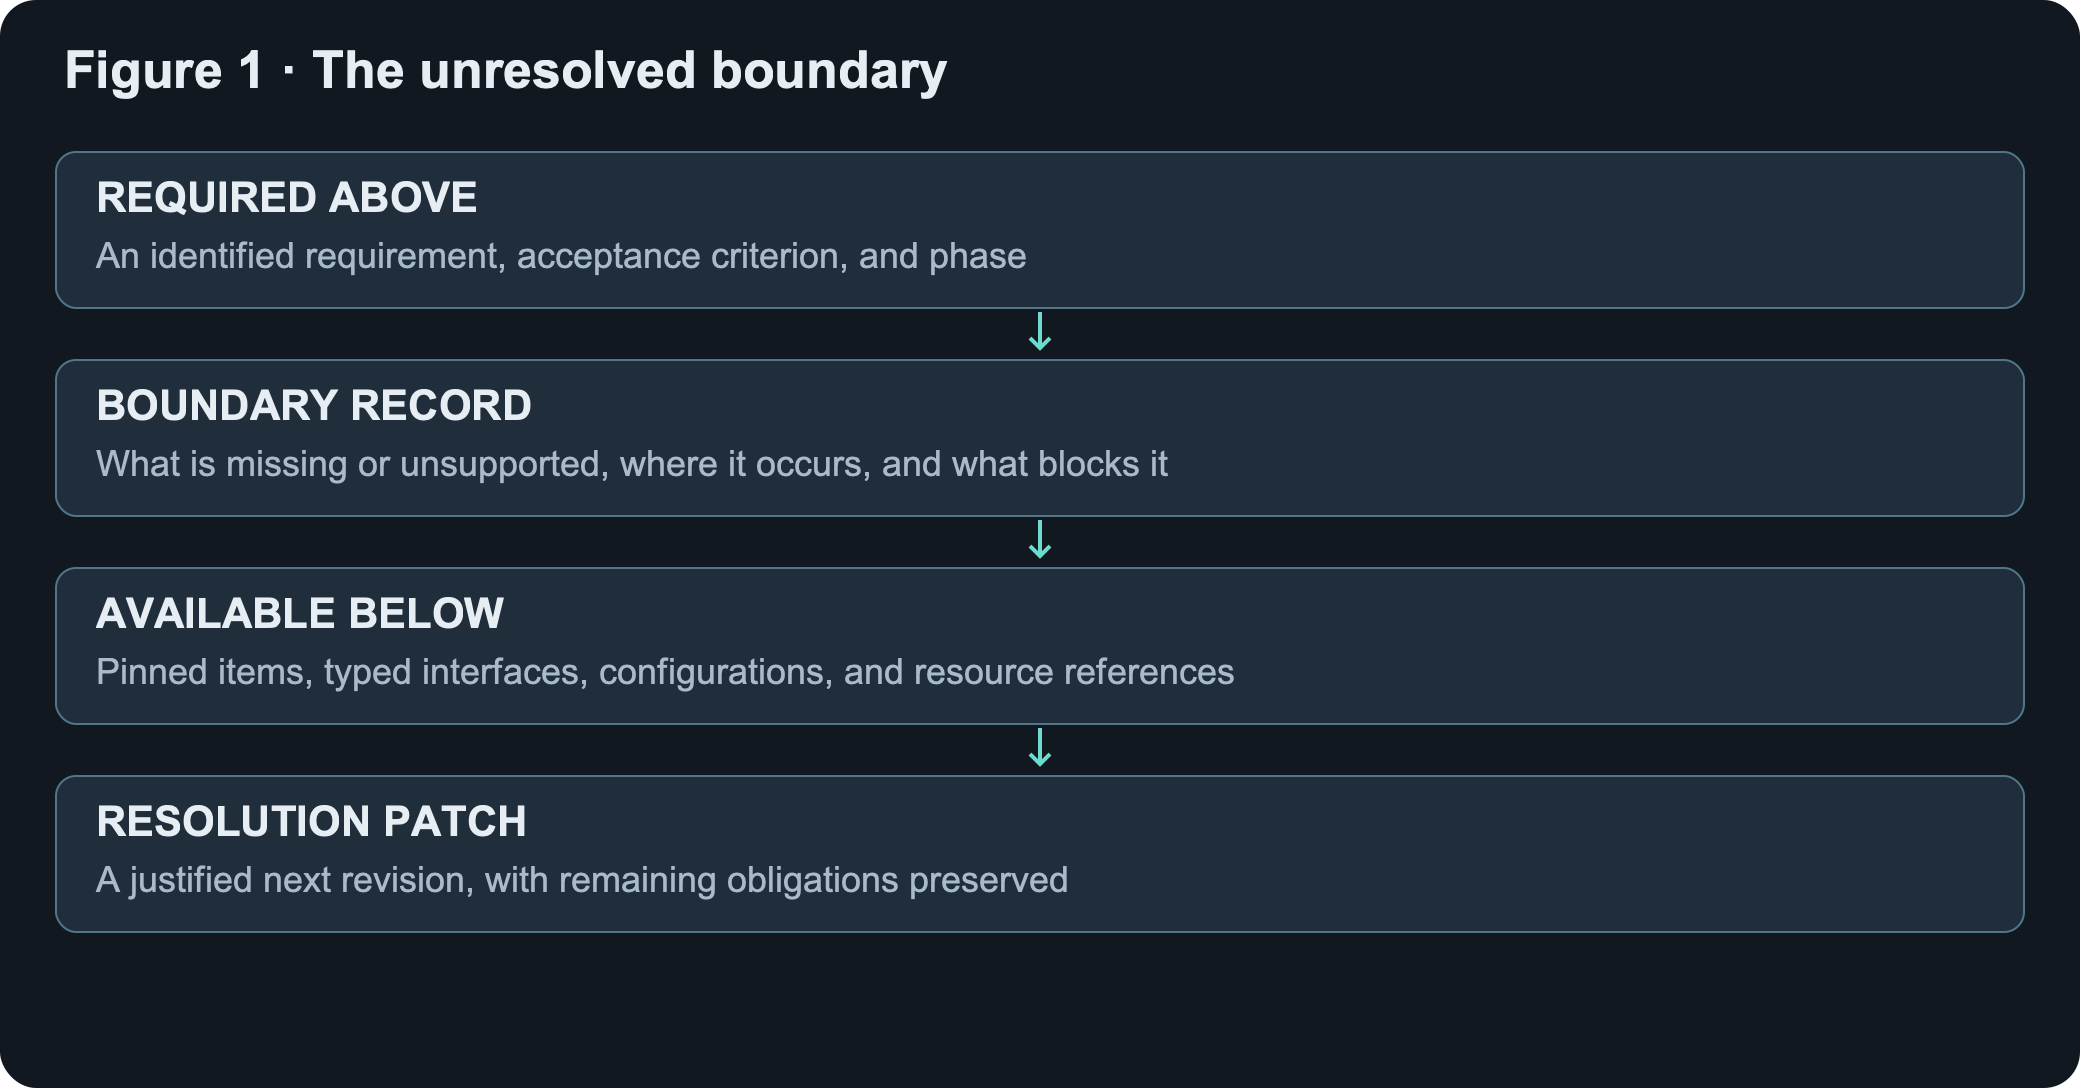

*Figure 1. Conceptual boundary map. Arrows show information used to write a proposal, not an executed flow.*

## 6. Selecting the Next Boundary

The baseline scheduler first resolves prerequisite order. A boundary whose prerequisites are unresolved is not ready for direct resolution; its prerequisite boundaries are considered instead. A missing prerequisite record is itself a gap. A dependency cycle is reported as a cycle boundary and is not hidden by arbitrary ordering. If a layer explicitly supports cyclic semantics, a dedicated rule may describe them; the conservative DAG profile does not.

Among ready boundaries, sort ascending by Kᵦ=(mandatoryRank, impactRank, baselineOrder, obligationID, boundaryID). mandatoryRank is 0 for mandatory and 1 for optional. impactRank is 0 for a known mandatory contradiction/conflict, 1 for an information or reference blocker, and 2 for other unresolved structure or evidence. baselineOrder is the stable requirement order. IDs are final tie-breakers, not significance scores. This declared convention prioritizes safety of claims and reproducibility, not optimal speed. Behavioral evidence boundaries are recorded as deferred in design-only mode and do not trigger experimental actions.

| Ordering stage | Rule | If unavailable |
| --- | --- | --- |
| Prerequisite gate | Select ready prerequisites before dependents | Create missing-dependency or cycle boundary |
| Mandatory rank | Mandatory before optional within selected scope | Mandatory flag must be clarified |
| Impact rank | Contradiction/conflict → information blocker → other | Use other; do not invent severity |
| Stable order | Baseline order, then obligation and boundary IDs | Assign stable IDs in input normalization |
| Deferred phase | No execution-based resolution in design-only mode | Retain deferred obligation with future criterion |

## 7. Candidate Records and Bounded Proposal Generation

A candidate a=(id,boundary,rule,operands,patch,guards,effects,residuals,provenance) is a proposed revision. It identifies exact occurrence/definition versions and before-state assumptions. A rule registry declares finite operand domains or an explicit enumeration cap. Deterministic enumeration, a language model, neural ranking, or a human may propose candidates. All enter the same gate. Reproducibility of selection does not make stochastic candidate generation deterministic: replay additionally requires its recorded proposals and versions. A proposal is not evidence for its own semantic claims.

| Candidate field | Required content | Failure disposition |
| --- | --- | --- |
| Rule and operands | Pinned rule version; existing/new occurrence IDs; definition references | Unknown references become gaps |
| Patch | Declared additions/edits/removals with before-state conditions | No hidden mutations |
| Guards | Typed, structural, authority, dependency and layer predicates | False rejects; unknown restricts commitment |
| Claimed effects | Requirement links and specific judgment changes | Effects require independent justification |
| Residuals | New/retained/superseded obligations | Dropping mandatory residuals rejects |
| Provenance | Proposer, input snapshot, assumptions, rule and policy versions | Unattributed candidates remain inadmissible |
| Enumeration record | Domain order, cap, observed batch, truncation reason | No completeness claim for truncated search |

## 8. Action Catalog and Preconditions

| Action | Applicability and required guard | Written result |
| --- | --- | --- |
| Clarify | Consequential ambiguity or conflicting intent; no authoritative answer recorded | A question and suspended boundary; answer creates versioned clarification |
| Resolve reference | Named resource/configuration requirement; supported reference and scope known | Versioned binding reference; no credentials embedded or activated |
| Reuse/select | Existing definition addresses a described obligation; occurrence identity policy explicit | New occurrence or explicit existing occurrence reference plus residuals |
| Decompose | Supported refinement pattern and explicit parent bridge | AND/OR child requirements; bridge unknown unless justified |
| Compose | Exact endpoints, admissible types/configuration and layer rule | Horizontal graph patch with required boundary obligations |
| Package | Complete membership/interface map and legal target layer | Higher occurrence referencing the same lower identities |
| Revise/backtrack | Recorded candidate conflict or exhausted branch; alternate snapshot available | New branch head; old history retained |
| Return | Closure, pending clarification, bounded exhaustion or no admissible candidates | Scoped outcome record with unresolved obligations |

These actions do not create missing primitive implementations. When no existing component or permitted rule can realize a leaf, return an unsupported-leaf gap with a proposed capability contract. Writing that contract is useful design progress, but it cannot be counted as an available executable library item. Registering a reusable definition in the shared library is also a separate operation; proposed instance-local items remain local until explicitly registered.

## 9. Admissibility and Judgment Discipline

Evaluate each guard using the evidence scope required by Paper 1. A judgment record carries a condition ID, subject versions, baseline, criterion, support references, contradiction references, assumptions, and disposition. Absence of proof is unknown, not false; conflicting records remain visible and yield outward unknown. There is no numerical confidence threshold in this baseline.

| Guard class | Met | Unknown or conflict | Violated |
| --- | --- | --- | --- |
| Representation invariant | Candidate may continue | Reject commitment; request missing structural information | Reject candidate |
| Semantic applicability | Condition supported in stated scope | Allow explicitly conditional design only if structure remains safe | Reject claimed realization or revise |
| Requirement satisfaction | Supports that specific criterion | Retain unmet/deferred obligation | Record unmet requirement and revise |
| Activation | Reference can be described without activation | Keep activation obligation deferred | Reject incompatible binding; no fallback invention |

Commit means accepting a revision of the design document, not approving its runtime behavior. A candidate with unknown semantic conditions may be retained as conditional only when all representation invariants are met and the policy permits such proposals. It must not set the associated requirement to met. No condition may be discharged using only a candidate’s assertion that it will hold.

## 10. Layer Profiles and Initial Composition Rules

Layer names alone are insufficient. Each profile declares the admissible item, horizontal relation, legal packaging target, interface mapping, supported cycles/state model, and closure criteria. The first concrete profile is Components → Composite. Composite → Flows and Flows → Processes below are proposed design profiles, not assertions that Langflow natively implements our hierarchy. Higher enterprise and organizational profiles remain explicitly uninstantiated; encountering them returns a layer-profile gap rather than inventing semantics.

| Layer/profile | Horizontal meaning | Packaging and retained obligations |
| --- | --- | --- |
| Components → Composite | Typed wiring among pinned component occurrences; conservative DAG unless a dedicated cycle rule exists | One Composite occurrence; preserve original members, crossing edges, unbound inputs, configuration and dependencies |
| Composite → Flows (proposed) | Directed task/data dependencies among exposed composite interfaces | Flow description with start/end, ordering, branch conditions and failure obligations; unresolved scheduling remains a gap |
| Flows → Processes (proposed) | Coordination of flow outcomes, actors, decisions and lifecycle constraints | Process description with triggers, accountable roles, completion and exception conditions; no claim of implemented orchestration |
| Higher planes | Only a supplied versioned profile may define composition | Otherwise stop that branch with missing-profile gap |

For a Components candidate, Rule C1 selects occurrences and exact typed endpoints, checks layer membership and required fields, and writes candidate Gc. Under a nominal compatibility profile, source output type must be explicitly accepted at the target; coercions require a named adapter. Rule C2 packages a selected subgraph H only after its boundary is enumerated: crossing edges in Gc, required unbound inputs, intentionally exposed ports, parameters and dependency references. External field bindings are distinct from data edges. Rule C3 unfolds by references to the same occurrence IDs; it is not a clone operation. Other profiles require their own explicit operational constraints before they can claim more than a proposed arrangement.

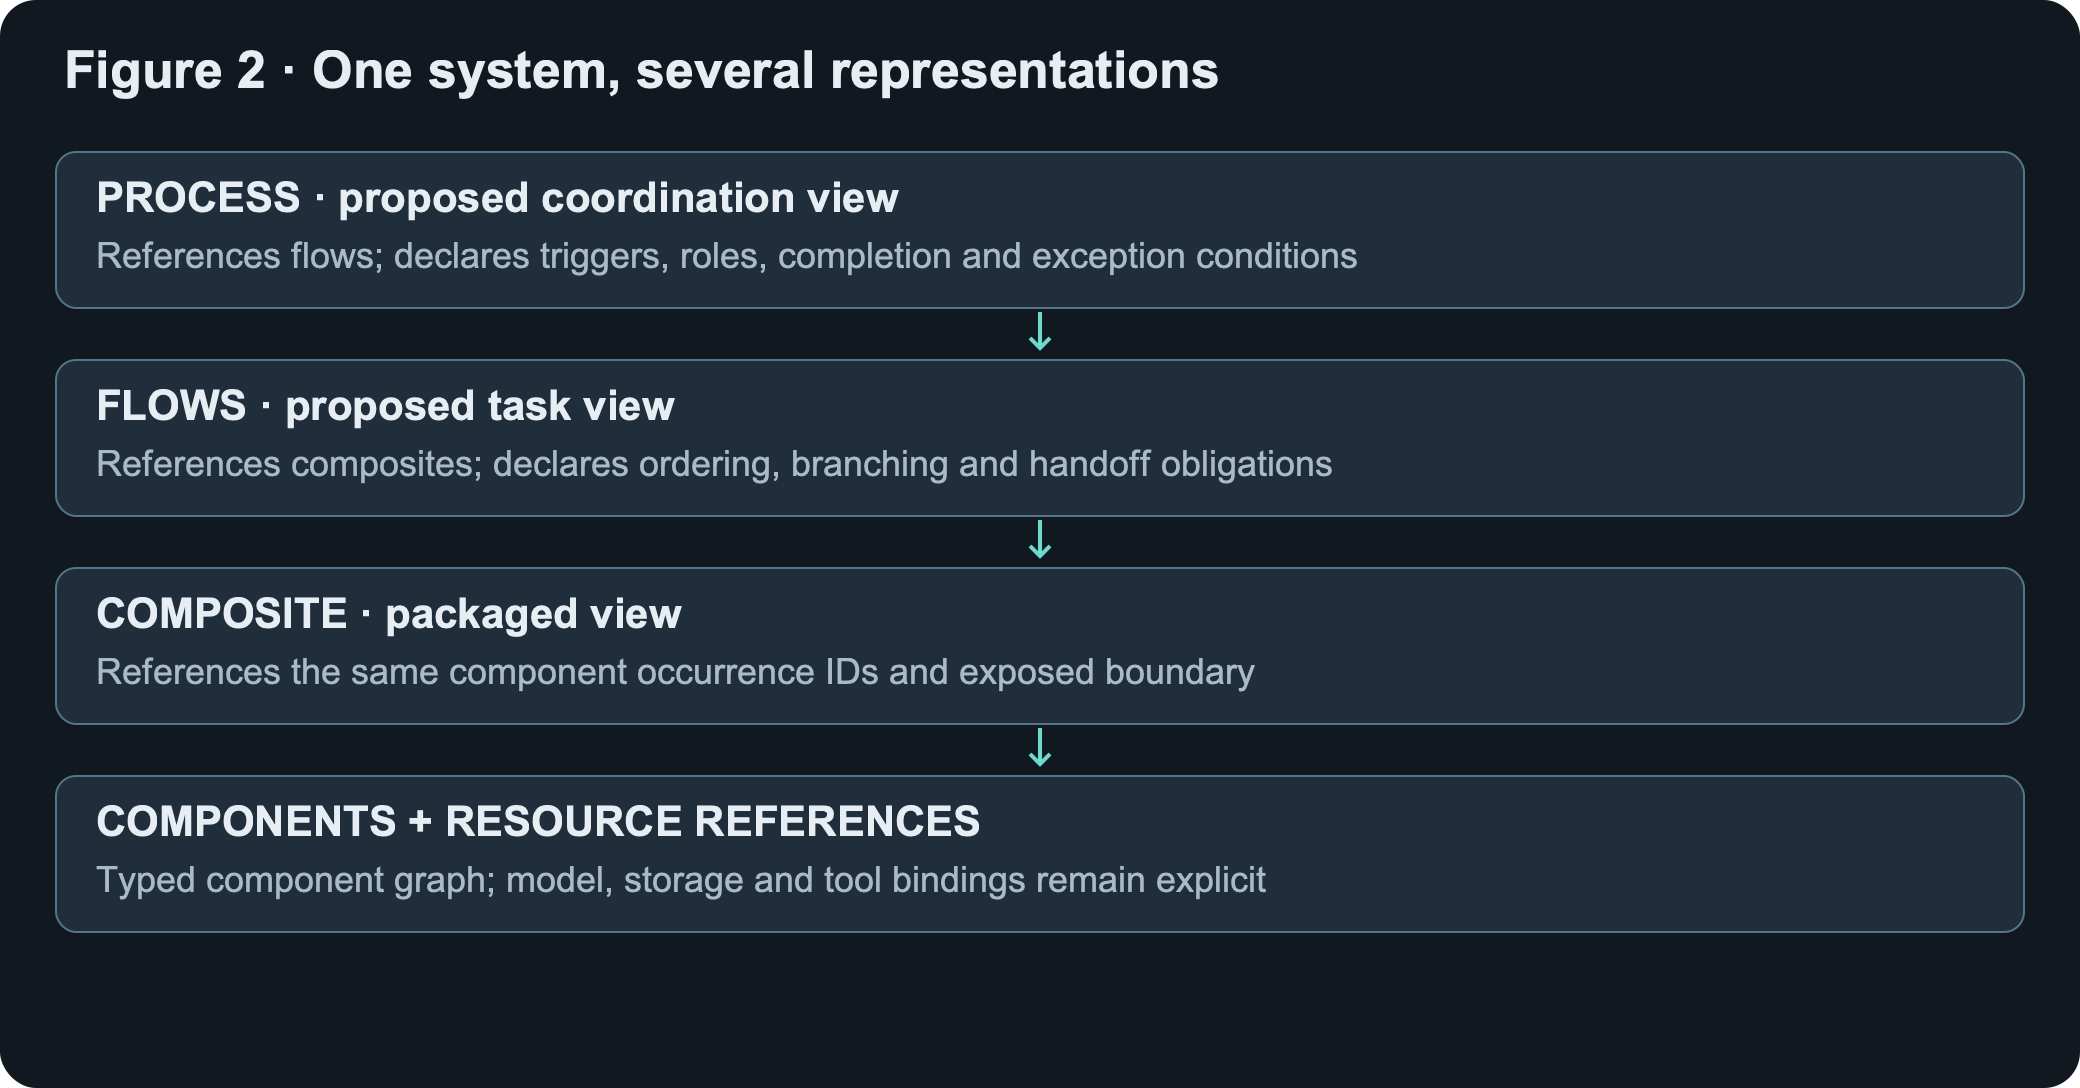

*Figure 2. Vertical arrows denote representation by references. Packaging neither duplicates members nor adds evidence. Only required, defined profiles participate.*

## 11. Comparing Candidates without Invented Scores

After admissibility filtering, use the baseline lexicographic key Kₐ=(conditionalRank, actionRank, unresolvedDesignCount, newDefinitionCount, editCount, ruleKey, operandKeys, candidateKey), ascending. conditionalRank is 0 when all applicability conditions are met, 1 for permitted conditional designs. actionRank follows the declared table. unresolvedDesignCount counts active mandatory design obligations after applying the proposal; it is not an estimate of correctness. Counts compare proposals within the same unchanged baseline and do not erase parent bridges. Stable final keys ensure repeatable tie-breaking.

| Action rank | Move | Rationale and limit |
| --- | --- | --- |
| 0 | Resolve an already specified reference | Prefer explicit binding over creating a new abstraction |
| 1 | Reuse/select a suitable existing item | Prefer grounded reuse; suitability still needs judgments |
| 2 | Compose admissible existing occurrences | Wire described capabilities before inventing a new definition |
| 3 | Package a requested assembly | Representation only; do not package just to manufacture progress |
| 4 | Decompose through a supported refinement | Useful when direct realization remains unsupported |
| 5 | Other profile-declared revision | Only explicit rule families; unsupported moves are gaps |

Clarification is an information gate, not a cheap ranked alternative to answering a known fact. Backtracking and return are control actions. This action order is a conservative baseline choice and may be suboptimal; it is not derived from experiments. Raw node count, model confidence, attractive diagrams, and unsupported expected rewards never override hard conditions. A future learned policy may reorder admissible candidates, but must disclose its objective and retain the invariant gate.

## 12. Transition Procedure and Branch Management

The following is specification pseudocode, not an implemented or executed program. Initialization normalizes record identities, pins versions, computes obligation coverage, and records any missing structural inputs. On each iteration: (1) reassess affected judgments; (2) evaluate terminal conditions; (3) select a ready boundary; (4) obtain a bounded candidate batch; (5) filter guards; (6) order admissible candidates; (7) record unchosen alternatives in the finite frontier; (8) accept one atomic patch if its invariants are met; (9) recompute affected obligations and continue. Each proposal-generation request, candidate assessment or branch expansion consumes an attempt before work begins. Empty batches consume an attempt too. Helpers must return within declared limits or be interruptible.

| Stage | Inputs → output | Required trace |
| --- | --- | --- |
| Reassess | Changed references → fresh/stale judgments and U | Invalidated evidence scopes |
| Select | Ready boundaries → selected boundary | Priority key and prerequisite status |
| Propose | Boundary + finite registry → bounded batch | Provenance, caps and omissions |
| Gate/order | Candidates + judgments → accepted conditional/admissible/rejected | Guard disposition and ordering key |
| Branch | Alternative candidates → finite snapshots | Discarded branches and capacity policy |
| Patch | Before Q + candidate → after Q | Exact edits and invariant judgments |
| Reassess/return | Updated state → next step or outcome | Residual obligations and scope |

Backtracking restores the branch-local Q, J and U associated with the alternate snapshot, then reassesses them against current pinned context. It does not restore the global attempt budget or erase T and V. If β, L, π or external evidence changes, treat it as a new decision epoch, record the change, and invalidate dependent judgments. A finite frontier can omit solutions; deterministic pruning is not evidence that pruned branches were impossible.

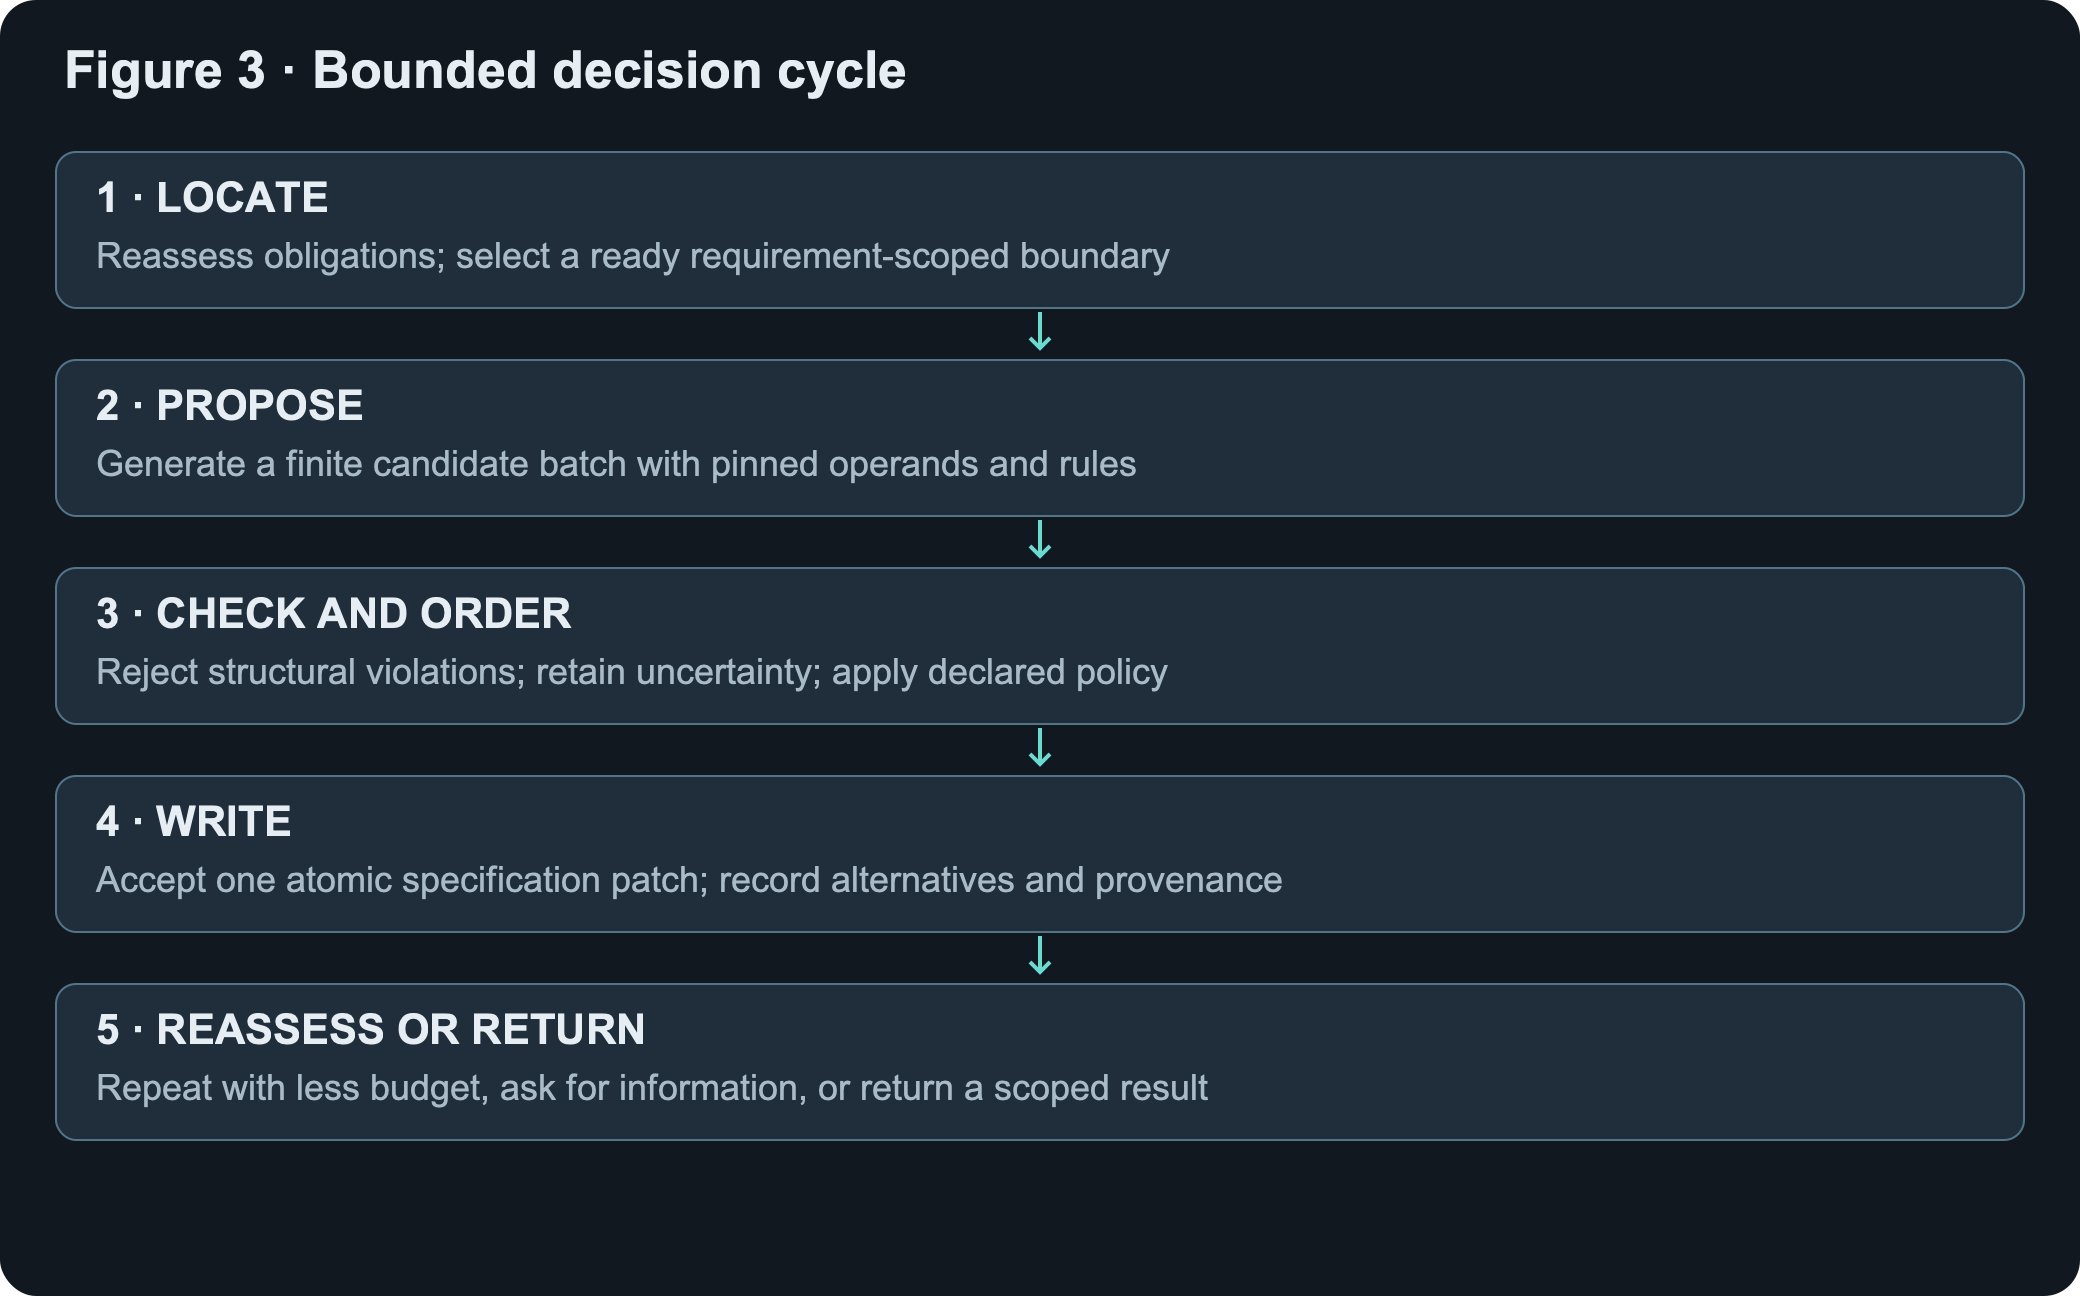

*Figure 3. Design procedure only. The return from reassessment to selection is iteration across document revisions, not a cycle inserted into the component DAG.*

## 13. Progress, Repetition, and Finite Stopping

Progress is recorded as a vector Δ=(resolved obligations, new obligations, invalidated judgments, structural edits, new ambiguities), not a single percentage. Decomposition can increase open obligations while improving clarity; therefore monotonically decreasing gap count is not assumed. Packaging alone does not discharge a behavioral requirement. A new state may be useful without being closer under every criterion.

| Mechanism | Precise baseline rule | Limitation |
| --- | --- | --- |
| State repetition | Canonicalize semantic Q, scoped obligations/judgments, versions and branch assumptions; exclude layout and wall-clock timestamps | Canonicalization is specified structurally, not graph-isomorphism solving |
| Equivalent action | Record boundary, rule, operands, patch and decision epoch; do not repeat unchanged attempt | New evidence or changed bindings can permit reassessment |
| Stable new IDs | Derive candidate-local IDs from branch and action identity; distinguish true multiplicity from accidental clones | Do not merge intentional stateful occurrences |
| Budget | Each attempted expansion/assessment consumes one of finite B attempts | Bounds attempts, not successful synthesis |
| Suboperation bound | Proposal/evidence services must terminate or permit interruption under policy limit | Without this assumption wall-clock termination is not established |
| Frontier bound | At most Fmax alternate states; deterministic eviction recorded | Search is incomplete when alternatives are pruned |

Conditional stopping argument: let b₀=B be finite and every attempted operation decrement b before invocation. No more than B charged attempts occur. If each helper returns or is interrupted in finite time and terminal bookkeeping is finite, the procedure returns a result in finite time. This argument says nothing about finding a solution, optimizing one, or proving behavioral correctness. Depth and candidate-size limits additionally prevent one attempt from constructing an unbounded record. B, Fmax, depth and size limits are mandatory policy inputs, not empirically chosen constants in this paper.

## 14. Outcome Records and Honest Completion

| Outcome | Necessary condition | What it does not mean |
| --- | --- | --- |
| Design-closed | Every mandatory design-phase criterion is met; requested structure/references/boundary records are complete; later-phase unknowns listed | Behavior correct or agent deployable |
| Satisfied in declared scope | Every mandatory requirement in unchanged scoped baseline has supported met judgment under its criterion | Universal or future-context correctness |
| Awaiting clarification | A consequential decision requires external answer; exact question recorded | An assumed answer is acceptable |
| Partial / budget-exhausted | A bounded attempt/frontier limit is reached; current record preserved | Intent impossible |
| Blocked within horizon | No admissible next move in declared registry, batch/frontier and assumptions | No solution exists outside that search horizon |
| Rejected candidate | A particular proposal violates mandatory guards | Entire intent rejected |

Outcome O=(kind,baseline,headRevision,scope,judgmentSummary,residualObligations,limits,traceRef,nextQuestions). Satisfaction is not vacuous when R is accidentally empty: an empty scoped baseline requires explicit authorization and is not an informative achievement. Design-only mode prohibits calls that would produce runtime evidence; it may describe such evidence obligations for Paper 3. Deployment readiness, if later assessed, must have its own activation and behavioral criteria.

## 15. Preservation Invariants and Audit Trail

| Invariant | Obligation on every accepted patch | Counterexample prevented |
| --- | --- | --- |
| Requirement coverage | Every mandatory baseline requirement retains judgment, obligations and trace | Deleting a difficult requirement raises completion |
| Unknown integrity | Unknown/conflicted conditions stay unresolved until criterion-supported resolution | Prompt instructions treated as proof |
| Identity | Definitions pinned; occurrences stable; packaging references same members | Wrapper silently clones a stateful agent |
| Boundary completeness | Retain crossing endpoints, exposed mappings and required unbound inputs | Disconnected input disappears inside wrapper |
| Layer legality | Profile and permitted packaging target recorded | Composite dropped into Components as a primitive |
| Evidence scope | Change invalidates affected judgments, including transitive dependencies | New model inherits old behavior evidence |
| Resource hygiene | Bindings reference authorized sources; no secret values embedded | API key copied into instance JSON |
| Trace continuity | Branch restoration retains attempts, rejected alternatives and reasons | Failed path erased to create a clean narrative |

Each trace event stores event identity, epoch, parent revision, boundary, selected action, candidate/guard references, ordering key, patch digest or exact patch, before/after references, residual dispositions, budget consumption and outcome. Hashes can detect content changes when implemented, but do not establish truth, authorship or immutable storage. The design requires append-only history at the data-model level; no tamper-proof implementation is claimed.

## 16. Worked Symbolic Case A — A Summarizer from Day Zero

Assume a pinned catalog with Chat Input, Agent and Chat Output interfaces described in Paper 1, and no saved Composite. The request is to write a proposed three-point summarizer. β includes mandatory design criteria for a typed graph, source-field mapping, model reference and Composite boundary; grounding and output quality remain mandatory behavioral obligations with later evidence criteria. All following states are authored symbolic examples, not observed runs.

| State/action | Written change | Remaining obligations |
| --- | --- | --- |
| A0: normalize | Separate design, behavior and activation criteria; pin three definition references | All realization and evidence obligations open |
| A1: resolve-reference | Record chosen model/provider reference if explicitly available | Actual authorization remains activation-deferred |
| A2: reuse/select | Create three distinct component occurrence IDs | Wiring and boundary not yet described |
| A3: compose C1 | ChatInput.message → Agent.input_value; Agent.response → ChatOutput.input_value | Task behavior unknown; source-text binding still required |
| A4: bind source field | Expose source text via ChatInput.input_value string field, separately from Message edges | No implicit string-to-Message equivalence claimed |
| A5: configure | Write three-point and grounding instructions; retain evidence criteria | Instructions establish configuration, not compliance |
| A6: package C2 | Proposed Summarizer Composite references same three IDs and mapped input/output | Behavior and activation remain deferred |
| A7: return | Design-closed only if all stated design criteria have supported judgments | No task satisfaction or successful execution claim |

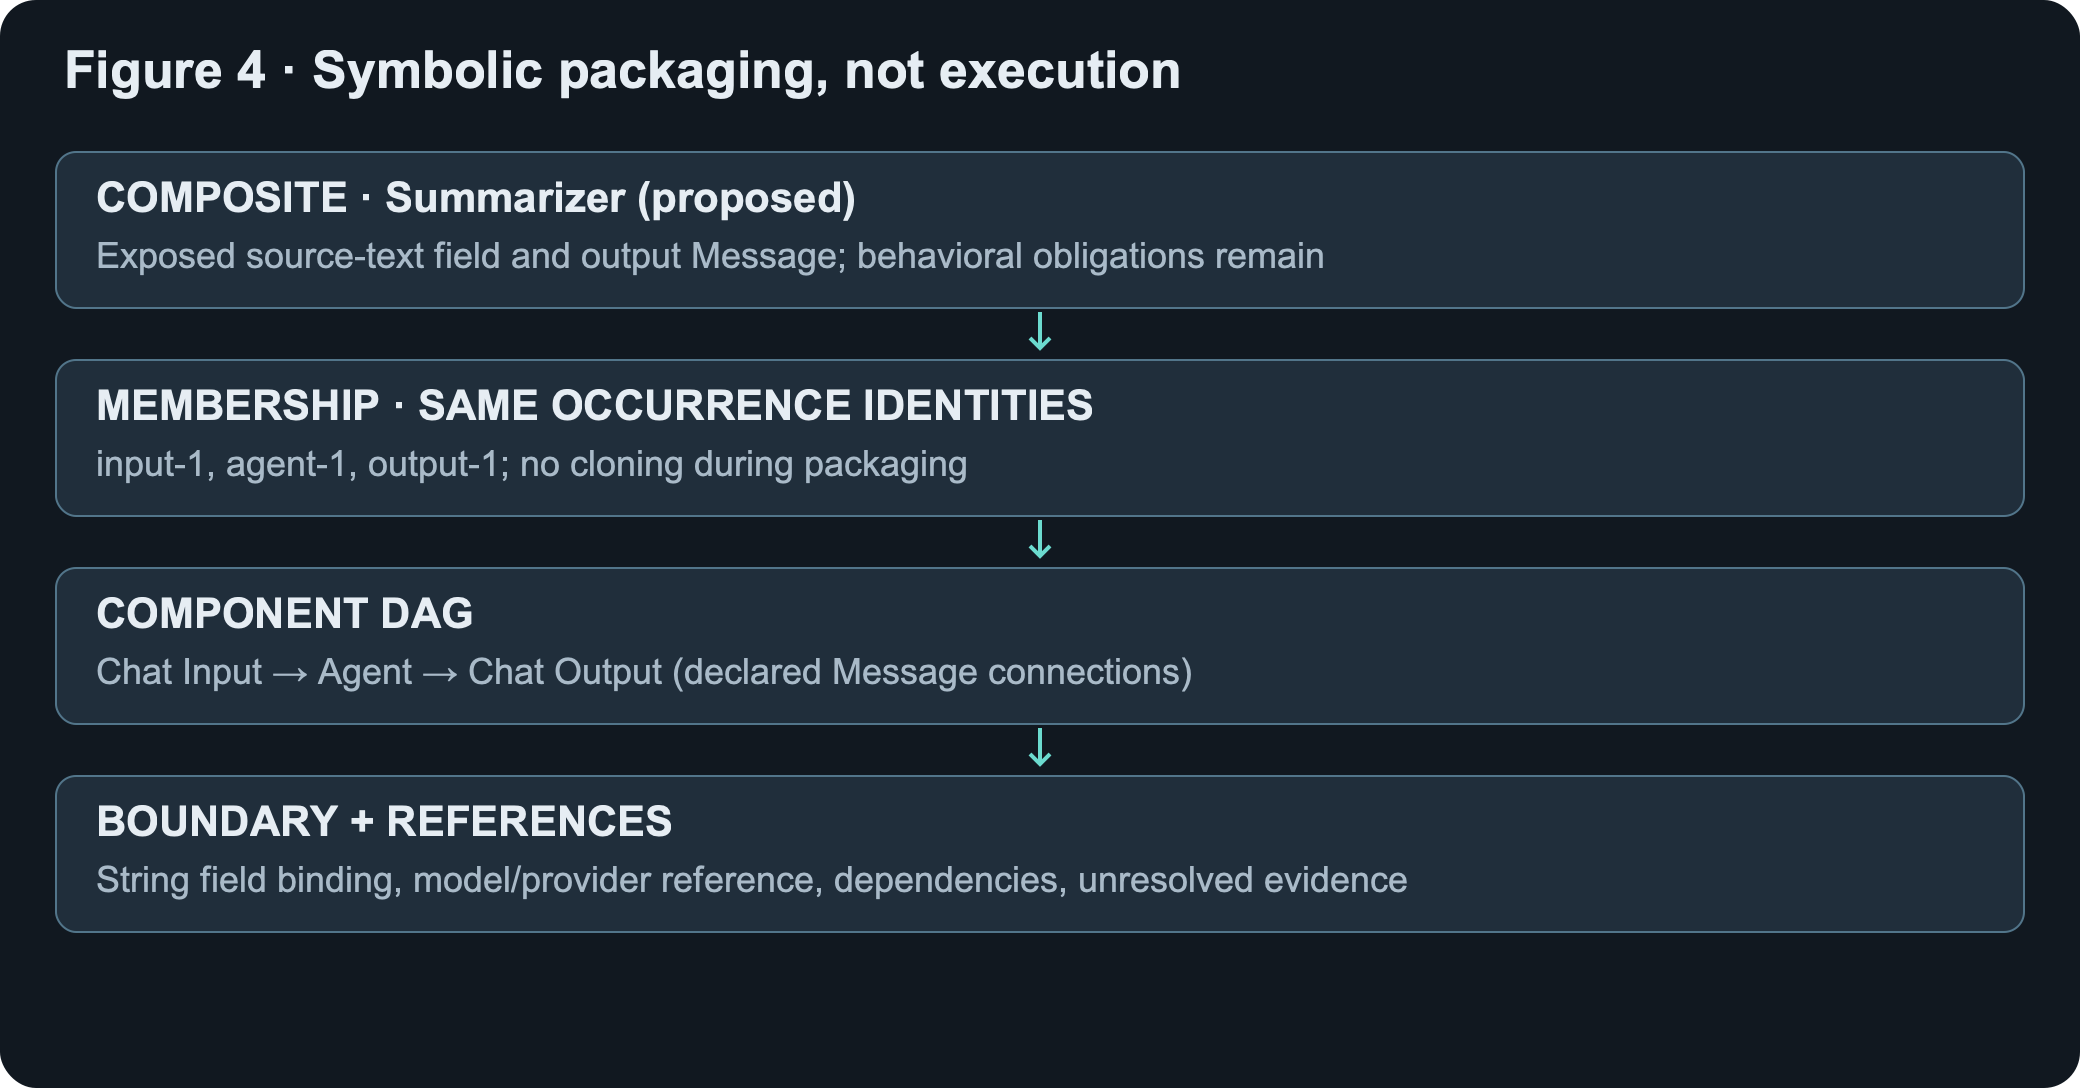

*Figure 4. The proposed upper item represents the lower assembly. Diagram arrows are descriptive and carry no claim of a successful run.*

## 17. Worked Symbolic Case B — Missing and Conflicting Information

Suppose a request demands local-only processing, but the selected model binding names a remote service. This known contradiction rejects that binding candidate. If the catalog contains a described local model reference but its capability/support is unknown, a local alternative may be represented conditionally; the locality and capability requirements remain separately judged. If no local realization exists within the pinned catalog, the controller records an unsupported dependency. It must not quietly remove local-only, use a remote fallback, or claim that a reference name proves deployment locality.

| Boundary | Permitted next move | Retained consequence |
| --- | --- | --- |
| Remote binding contradicts local-only | Reject binding and inspect explicit local alternatives | Mandatory locality unchanged |
| Meaning of local is ambiguous | Ask whether on-device or private-network is intended | Awaiting clarification, no invented scope |
| Evidence supports and contradicts capability | Preserve both records and mark outward unknown | No satisfied requirement |
| No permitted local candidate in horizon | Return scoped blocked/partial with missing resource contract | No impossibility claim |
| Missing higher-layer profile | Keep existing lower assembly; return profile gap | Do not invent a Process or Enterprise merely to fill a plane |

## 18. Alternative Methods and Why the Controller Is Method-Agnostic

The baseline separates proposal quality from admissibility. Deterministic rules can enumerate a declared grammar; models can suggest decompositions; learned rankers can prioritize candidates; multiple agents can independently propose alternatives. Their outputs are proposals sharing the same boundary, baseline and record format. Consensus between agents is not evidence that a requirement holds. A critic can identify a counterexample, but its claim still needs recorded grounds. No method is assumed superior here.

| Method | Allowed contribution | Required control |
| --- | --- | --- |
| Deterministic grammar | Enumerate explicit legal rule/operand combinations | Declare grammar, limits and omitted domains |
| Language model | Suggest descriptions, refinements and candidate patches | Pin inputs/outputs; do not grant proof authority |
| Neural ranker | Reorder admissible candidates | Version ranking policy; keep mandatory guards |
| Multiple agents | Produce separate candidates or critique records | Shared baseline; preserve disagreements; avoid vote-as-proof |
| Hybrid | Combine bounded proposals with deterministic checks | Account for every attempt and unresolved semantic judgment |

## 19. Visual and Data-Structure Register

Tables accompany the data structures rather than leaving their meaning inside formulas alone. Figures 1–4 are authored static explanatory diagrams. They contain no measured quantities, simulated telemetry or executable flow. No statistical observations are introduced in this paper, so no statistical chart or invented dataset is supplied. Paper 3 may add empirical plots only after its study design and observations exist.

| Artifact | Human question answered | Status |
| --- | --- | --- |
| State/requirement/boundary/candidate tables | What information must the controller preserve? | Specified in Sections 3–7 |
| Action/guard/profile/policy tables | When is a move legal and how is it selected? | Specified in Sections 8–11 |
| Transition/progress/outcome/invariant tables | How does iteration remain bounded and honest? | Specified in Sections 12–15 |
| Figures 1 and 3 | Where is the mismatch and how does the controller respond? | Static conceptual diagrams |
| Figures 2 and 4 | How is one system represented across planes? | Static conceptual diagrams |
| Symbolic case tables | What changes and what remains unknown? | Authored examples; no execution |
| Statistical graphics | What did experiments measure? | Not applicable; deferred to Paper 3 |

## 20. Limitations, Threats to Validity, and Review Status

The policy is specified, not empirically validated. Lexicographic priorities may choose costly or unhelpful paths; bounded search can miss good assemblies. Semantic descriptions may be too weak to support refinement bridges, dependency closure, or behavioral implication. Graph/state canonicalization preserves deliberate identities and therefore does not eliminate every isomorphic or semantically equivalent state. Full semantic equivalence is not assumed decidable. Proposed higher-layer profiles need domain-specific refinement. Dynamic resource changes require revalidation beyond this static snapshot. These limits constrain the claims rather than being hidden in a success score.

| Concern | Treatment in manuscript | Outstanding work |
| --- | --- | --- |
| Confirmation bias | Unsupported claims remain unknown; contradictory case included | Independent review and later empirical adversaries |
| Weak methods | Exact baseline, phase distinction and limits specified | Implementation/evaluation in Paper 3 |
| Missing alternatives | Several proposal methods and explicit pruning disclosure | Comparative study not performed |
| Overclaiming completion | Design closure separated from satisfaction/readiness | No new correctness proof |
| Review status | Editorial consistency pass by drafting assistant only | No independent Paper 2 review or external peer review claimed |

This manuscript completes the theoretical specification within its stated scope. It has not undergone a new independent peer-review round. Paper 1’s internal AI reviews do not transfer to this paper. No tests, model calls, workflow execution, performance measurements or experimental observations were performed to substantiate Paper 2. Checking that the manuscript is saved and readable is publication handling, not testing the proposed algorithm.

## 21. Conclusion and Handoff to Paper 3

Boundary resolution is specified as a bounded controller over versioned descriptions and explicit obligations. It selects a ready mismatch, proposes finite rule applications, rejects unsupported structural commitments, ranks admissible proposals under a transparent baseline, writes one auditable revision, and returns a scoped result when closure, information needs or limits require it. The same system can be represented on different planes while preserving identities and unresolved claims. The algorithm writes an instance specification; it does not turn a symbolic proposal into operational evidence.

| Established as design | Reserved for Paper 3 or later |
| --- | --- |
| Record schemas, priority keys, action guards and layer-profile interface | Executable implementation and conformance evaluation |
| Conservative Components → Composite rules and proposed higher profiles | Domain-specific profile performance and coverage |
| Finite stopping under stated helper/budget assumptions | Observed latency, cost and robustness |
| Symbolic successful and blocked paths | Designed experiments, baselines, datasets and measured outcomes |
| Explicit proposal/validation separation | Whether model, deterministic, neural or multi-agent methods improve generation |

Paper 3 is intentionally not drafted here. The next research stage can design and test experiments against these stated contracts without retroactively treating the present symbolic cases as observations. Before that stage, the user may choose an independent conceptual review or revise the baseline policy. Remaining empirical questions do not prevent this theory manuscript from being complete within its declared claim boundary.

## References and Provenance

[1] Project manuscript: From Components to Instances: Iterative Composition, final conceptual revision; knowledge/research/reviews/paper-1-instance-generation/manuscript-final.html. Inherits its definitions and limitations; historical experiments are not new evidence for Paper 2.

[2] Langflow, Components overview: [https://docs.langflow.org/concepts-components](https://docs.langflow.org/concepts-components) . Consulted for component inputs, outputs, parameters and typed ports, not for our proposed multilayer controller. The deployed local version may differ from current documentation; the symbolic summarizer interfaces are those recorded in Paper 1.

[3] JSON Schema Draft 2020-12, JSON Schema Validation: [https://json-schema.org/draft/2020-12/json-schema-validation](https://json-schema.org/draft/2020-12/json-schema-validation) . Structural validation vocabulary; not a proof of instance behavior.

[4] Project domain model: knowledge/instance-machine/[domain-model.md](https://domain-model.md). User-confirmed vocabulary for layers, instances, requirements and boundary resolution; not external validation.

Authoring disclosure: AI-assisted theoretical manuscript developed from the user’s research direction. Diagrams and symbolic records are authored explanations. Policy choices are explicitly proposed, not discovered from data. Manuscript revision: theoretical completion 1; empirical status: not tested.